<div style="border:1px solid #d8e2ef; border-radius:18px; padding:26px 30px; background:#ffffff;">
  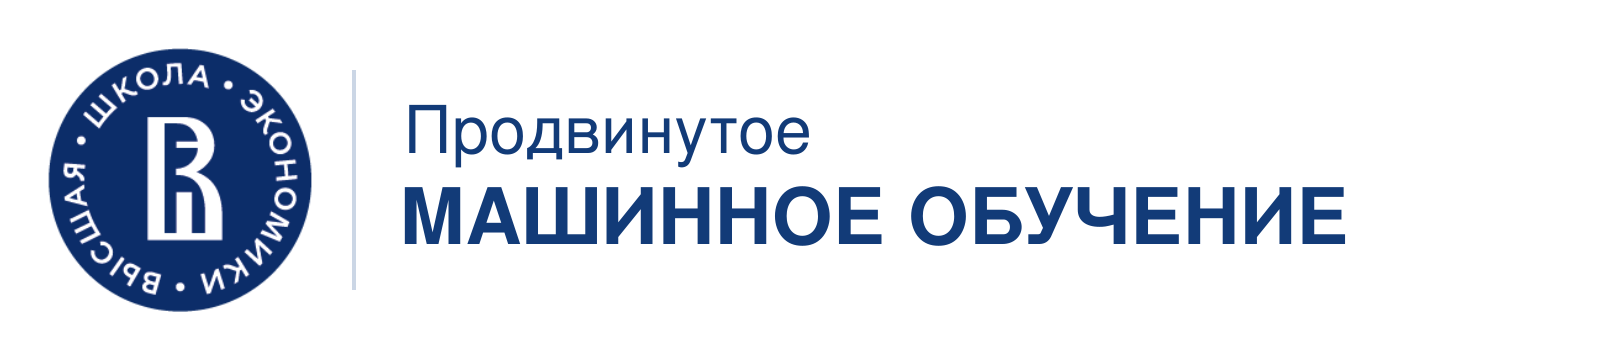

# Практика к лекциям
## Надёжность ML-экспериментов
</div>


# Лекция 1

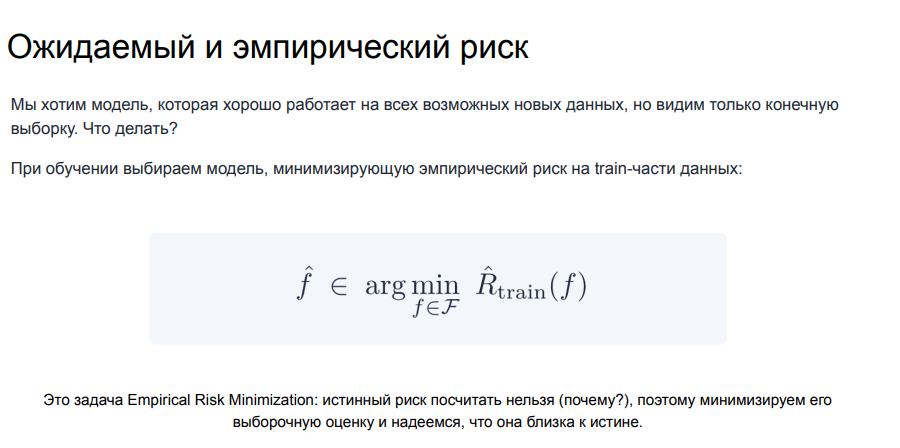

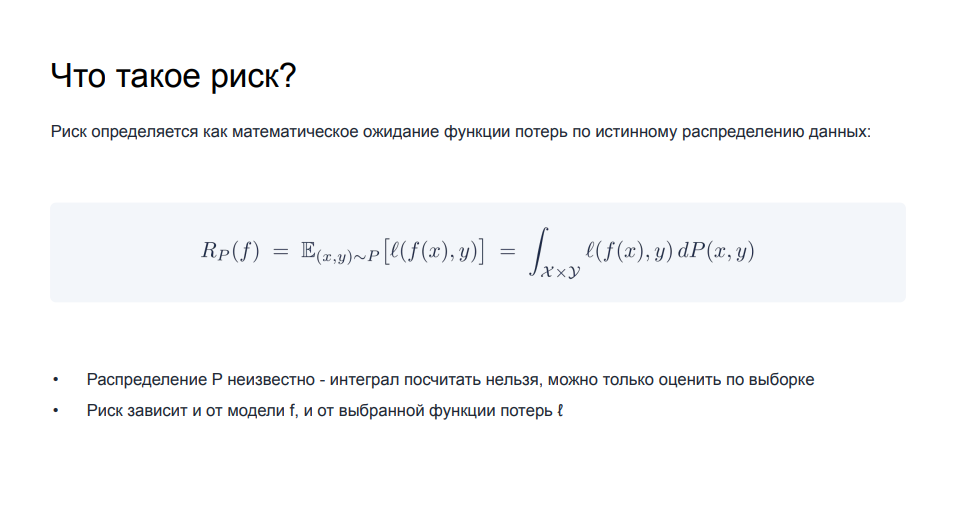

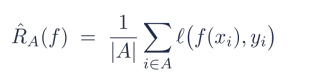

In [5]:
import numpy as np

# наши пять точек
x = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y = np.array([2.0, 5.0, 5.0, 8.0, 11.0])

In [6]:
candidates = {
    "f1: a=1": 1.0,
    "f2: a=2": 2.0,
    "f3: a=3": 3.0,
}

In [7]:
def empirical_risk(a, x, y):
    # f(x) = a * x
    pred = a * x
    # штраф одной точки: (pred - y)^2
    losses = (pred - y) ** 2
    # средний штраф по train — hat R_train
    return losses.mean(), losses

In [8]:
print("x =", x)
print("y =", y)
print()

x = [1. 2. 3. 4. 5.]
y = [ 2.  5.  5.  8. 11.]



In [9]:
risks = {}
for name, a in candidates.items():
    risk, losses = empirical_risk(a, x, y)
    risks[name] = risk
    print(f"{name}")
    print("  предсказания:", a * x)
    print("  штрафы по точкам:", losses)
    print("  сумма штрафов:", losses.sum())
    print("  hat R_train = сумма / 5 =", risk)
    print()

best_name = min(risks, key=risks.get)
print("ERM выбирает:", best_name, "с hat R_train =", risks[best_name])

f1: a=1
  предсказания: [1. 2. 3. 4. 5.]
  штрафы по точкам: [ 1.  9.  4. 16. 36.]
  сумма штрафов: 66.0
  hat R_train = сумма / 5 = 13.2

f2: a=2
  предсказания: [ 2.  4.  6.  8. 10.]
  штрафы по точкам: [0. 1. 1. 0. 1.]
  сумма штрафов: 3.0
  hat R_train = сумма / 5 = 0.6

f3: a=3
  предсказания: [ 3.  6.  9. 12. 15.]
  штрафы по точкам: [ 1.  1. 16. 16. 16.]
  сумма штрафов: 50.0
  hat R_train = сумма / 5 = 10.0

ERM выбирает: f2: a=2 с hat R_train = 0.6


In [41]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import hinge_loss, log_loss

x = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y = np.array([2.0, 5.0, 5.0, 8.0, 11.0])

# F теперь «все прямые ax+b», не три штуки
model = LinearRegression()
model.fit(x.reshape(-1, 1), y)   # внутри сидит ERM по MSE
pred_train = model.predict(x.reshape(-1, 1))
train_risk = mean_squared_error(y, pred_train)

print("найденные a, b:", model.coef_[0], model.intercept_)
print("hat R_train:", train_risk)

найденные a, b: 2.1000000000000005 -0.10000000000000142
hat R_train: 0.5399999999999997


In [42]:
x = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y = np.array([2.0, 5.0, 5.0, 8.0, 11.0])

# F теперь «все прямые ax+b», не три штуки
model = LinearRegression()
model.fit(x.reshape(-1, 1), y)   # внутри сидит ERM по MSE
pred_train = model.predict(x.reshape(-1, 1))
train_risk = mean_absolute_error(y, pred_train)

print("найденные a, b:", model.coef_[0], model.intercept_)
print("hat R_train:", train_risk)

найденные a, b: 2.1000000000000005 -0.10000000000000142
hat R_train: 0.6


In [43]:
x = np.array([1., 2., 3., 4., 5., 6.])
y = np.array([2., 4., 6., 8., 12., 11.])

In [44]:
A_train, A_val, A_test = [0, 1, 2, 3], [4], [5]

In [45]:
def emp_risk(y_true, y_pred, kind="mse"):
    if kind == "mse":
        return np.mean((y_pred - y_true) ** 2)
    if kind == "mae":
        return np.mean(np.abs(y_pred - y_true))

In [46]:
f = 2 * x

In [47]:
print("numpy  train MSE", emp_risk(y[A_train], f[A_train], "mse"))
print("numpy  test  MSE", emp_risk(y[A_test],  f[A_test],  "mse"))
print("numpy  gap      ", emp_risk(y[A_test], f[A_test], "mse") - emp_risk(y[A_train], f[A_train], "mse"))

print("sklearn train MSE", mean_squared_error(y[A_train], f[A_train]))
print("sklearn test  MSE", mean_squared_error(y[A_test], f[A_test]))
print("sklearn train MAE", mean_absolute_error(y[A_train], f[A_train]))

numpy  train MSE 0.0
numpy  test  MSE 1.0
numpy  gap       1.0
sklearn train MSE 0.0
sklearn test  MSE 1.0
sklearn train MAE 0.0


In [48]:
X_tr, X_te, y_tr, y_te = train_test_split(
    x.reshape(-1, 1), y, test_size=2, random_state=0
)
lin = LinearRegression().fit(X_tr, y_tr)          # min hat R_train по MSE
print("fit a,b", float(lin.coef_[0]), float(lin.intercept_))
print("sklearn gap after fit",
      mean_squared_error(y_te, lin.predict(X_te))
      - mean_squared_error(y_tr, lin.predict(X_tr)))

fit a,b 2.4 -0.6999999999999993
sklearn gap after fit 3.419999999999998


In [50]:
from sklearn.svm import LinearSVC
# ---------- классификация: BCE и hinge ----------
# 10 одинаковых эпизодов, 7 пенальти (y=+1), 3 не пенальти (y=-1)
y_pm = np.array([1] * 7 + [-1] * 3)
eta = 0.7
f_star = 1.0
# средний hinge по формуле методички
e_hinge = eta * max(0, 1 - f_star) + (1 - eta) * max(0, 1 + f_star)
print("hinge E(f=1), eta=0.7", e_hinge)          # 0.6

# sklearn ждёт decision_function и метки ±1
print("sklearn hinge_loss",
      hinge_loss(y_pm, np.full_like(y_pm, f_star, dtype=float)))

# BCE: вероятность пенальти p
p = np.full(10, 0.7)
y01 = (y_pm == 1).astype(float)
bce_np = -np.mean(y01 * np.log(p) + (1 - y01) * np.log(1 - p))
print("numpy  BCE", bce_np)
print("sklearn log_loss", log_loss(y01, p))

# LinearSVC минимизирует hinge, не вероятность
X_cls = np.ones((10, 1))
svc = LinearSVC(C=1.0, max_iter=5000).fit(X_cls, y_pm)
print("SVM decision на таком же x", float(svc.decision_function([[1.0]])))
print("это не оценка eta")

hinge E(f=1), eta=0.7 0.6000000000000001
sklearn hinge_loss 0.6
numpy  BCE 0.6108643020548935
sklearn log_loss 0.6108643020548935
SVM decision на таком же x 0.39025946119336685
это не оценка eta


In [51]:
# ---------- PIT: продажи, горизонт 2 дня ----------
days = np.arange(1, 8)
sales = np.array([10, 12, 9, 15, 8, 14, 11])
# признак в день t — продажи вчера; таргет — сумма следующих двух дней
feat = np.r_[np.nan, sales[:-1]]
target = sales[1:-1] + sales[2:]          # для t=1..5
label_end = days[:5] + 2                  # последняя дата, нужная для y
print("t, feat, y, label_end")
for t, a, b, c in zip(days[:5], feat[:5], target, label_end):
    print(int(t), a, b, int(c))

c = 4  # валидация начинается в день 4
ok = label_end < c
print("в train при старте val=4 годятся дни", days[:5][ok])

t, feat, y, label_end
1 nan 21 3
2 10.0 24 4
3 12.0 23 5
4 9.0 22 6
5 15.0 25 7
в train при старте val=4 годятся дни [1]


In [52]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(0)

# мир: в точке x=0 правда равна 2, шум ±1
def draw_y(n):
    return 2.0 + rng.choice([-1.0, 1.0], size=n)

TRUE_F = 2.0
NOISE = 1.0          # sigma_eps^2, посчитали выше
X0 = np.array([[0.0]])

# --- оценка bias/var по многим выборкам размера 1 ---
def collect_preds(make_model, n_train=1, n_runs=2000):
    preds = []
    for _ in range(n_runs):
        y_tr = draw_y(n_train)
        X_tr = np.zeros((n_train, 1))
        model = make_model()
        model.fit(X_tr, y_tr)
        preds.append(float(model.predict(X0)[0]))
    return np.array(preds)

def report(name, preds):
    mean_pred = preds.mean()
    bias2 = (mean_pred - TRUE_F) ** 2
    var = preds.var()
    err = NOISE + bias2 + var
    print(f"{name:18s} E[fhat]={mean_pred:.3f}  bias2={bias2:.3f}  var={var:.3f}  err={err:.3f}")

# константа 0: «дерево глубины 0» имитируем Ridge с огромным штрафом
# проще — модель, которая всегда предсказывает среднее train, но мы заменим нулём вручную
class AlwaysZero:
    def fit(self, X, y): return self
    def predict(self, X): return np.zeros(len(X))

class RepeatTrain:          # n_train=1: повторяет единственную точку
    def fit(self, X, y):
        self.v = float(y[0]); return self
    def predict(self, X):
        return np.full(len(X), self.v)

print("формула Err = 1 + bias2 + var")
report("всегда 0", collect_preds(AlwaysZero, n_train=1))
report("повтор train", collect_preds(RepeatTrain, n_train=1))

# sklearn: одно и то же x, меняется только глубина
# добавим чуть разные x, иначе дерево глубины 1 нечему резать
def make_xy(n=20):
    X = rng.uniform(-1, 1, size=(n, 1))
    y = 2.0 * X[:, 0] + rng.choice([-1.0, 1.0], size=n)
    return X, y

X_te = np.linspace(-1, 1, 40).reshape(-1, 1)
y_te_mean = 2.0 * X_te[:, 0]     # правда без шума, чтобы видеть bias

def run_depth(depth, n_runs=100):
    preds = []
    train_mse, test_mse = [], []
    for _ in range(n_runs):
        X_tr, y_tr = make_xy(20)
        tree = DecisionTreeRegressor(max_depth=depth, random_state=0)
        tree.fit(X_tr, y_tr)
        preds.append(tree.predict(X_te))
        y_te = 2.0 * X_te[:, 0] + rng.choice([-1.0, 1.0], size=len(X_te))
        train_mse.append(mean_squared_error(y_tr, tree.predict(X_tr)))
        test_mse.append(mean_squared_error(y_te, tree.predict(X_te)))
    P = np.vstack(preds)
    bias2 = ((P.mean(axis=0) - y_te_mean) ** 2).mean()
    var = P.var(axis=0).mean()
    print(f"depth={depth!s:>4}  train={np.mean(train_mse):.3f}  test={np.mean(test_mse):.3f}  "
          f"gap={np.mean(test_mse)-np.mean(train_mse):.3f}  bias2={bias2:.3f}  var={var:.3f}")

print("\nsklearn деревья")
run_depth(1)
run_depth(3)
run_depth(None)

# Ridge: большой alpha = уже полка, bias↑ variance↓
def run_ridge(alpha, n_runs=100):
    preds = []
    for _ in range(n_runs):
        X_tr, y_tr = make_xy(20)
        m = Ridge(alpha=alpha).fit(X_tr, y_tr)
        preds.append(m.predict(X_te))
    P = np.vstack(preds)
    bias2 = ((P.mean(axis=0) - y_te_mean) ** 2).mean()
    var = P.var(axis=0).mean()
    print(f"Ridge alpha={alpha:<6} bias2={bias2:.3f}  var={var:.3f}")

print("\nsklearn Ridge")
run_ridge(0.0)
run_ridge(10.0)

формула Err = 1 + bias2 + var
всегда 0           E[fhat]=0.000  bias2=4.000  var=0.000  err=5.000
повтор train       E[fhat]=1.986  bias2=0.000  var=1.000  err=2.000

sklearn деревья
depth=   1  train=0.913  test=1.645  gap=0.732  bias2=0.132  var=0.515
depth=   3  train=0.325  test=1.773  gap=1.448  bias2=0.011  var=0.740
depth=None  train=0.000  test=2.033  gap=2.033  bias2=0.012  var=0.996

sklearn Ridge
Ridge alpha=0.0    bias2=0.002  var=0.101
Ridge alpha=10.0   bias2=0.547  var=0.079


In [53]:
import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.base import clone

rng = np.random.default_rng(0)

# шесть точек как в разборе
y = np.array([1., 3., 2., 8., 2., 4.])
X = np.arange(6).reshape(-1, 1)   # фиктивный x, модель ниже всё равно среднее

# ----- обычный код: K-fold руками -----
kf = KFold(n_splits=3, shuffle=False)
fold_risks = []
for fold, (tr, va) in enumerate(kf.split(X), start=1):
    # hat f^(-k) = среднее train
    pred = y[tr].mean()
    risk = mean_squared_error(y[va], np.full(len(va), pred))
    fold_risks.append(risk)
    print(f"фолд {fold}: train {y[tr]}  mean={pred:.2f}  val {y[va]}  R={risk:.2f}")

cv_hat = np.mean(fold_risks)
print("R_CV вручную", cv_hat)

# ----- sklearn: то же самое -----
dummy = DummyRegressor(strategy="mean")
mse_scorer = make_scorer(mean_squared_error, greater_is_better=False)
# cross_val_score для MSE часто возвращает отрицание, берём прямой цикл как в практике
sk_risks = []
for tr, va in kf.split(X):
    m = clone(dummy)
    m.fit(X[tr], y[tr])
    sk_risks.append(mean_squared_error(y[va], m.predict(X[va])))
print("R_CV sklearn-цикл", np.mean(sk_risks))

# ----- победитель по CV: три глубины дерева -----
# чуть больше точек, иначе дерево с глубиной 3 запоминает всё
X2 = rng.normal(size=(30, 1))
y2 = 2 * X2[:, 0] + rng.normal(scale=1.0, size=30)

inner = KFold(n_splits=3, shuffle=True, random_state=0)
search = GridSearchCV(
    DecisionTreeRegressor(random_state=0),
    param_grid={"max_depth": [1, 2, 4]},
    scoring="neg_mean_squared_error",
    cv=inner,
)
search.fit(X2, y2)
print("победитель по CV", search.best_params_, "CV-MSE", -search.best_score_)
print("это цифра победителя, она оптимистична")

# честнее: внешний фолд, которого не было в argmin
outer = KFold(n_splits=3, shuffle=True, random_state=1)
outer_scores = []
for tr, te in outer.split(X2):
    s = GridSearchCV(
        DecisionTreeRegressor(random_state=0),
        param_grid={"max_depth": [1, 2, 4]},
        scoring="neg_mean_squared_error",
        cv=KFold(3, shuffle=True, random_state=0),
    )
    s.fit(X2[tr], y2[tr])
    outer_scores.append(mean_squared_error(y2[te], s.predict(X2[te])))
print("оценка после nested CV", np.mean(outer_scores))

# ----- утечка через соседа -----
# строки: A, B, C; столбцы: S_AB, X, S_BC, Y, Z
# 1 = факт просмотра. C смотрит S_BC позже, чем мы спрашиваем X у A
users = ["A", "B", "C"]
items = ["S_AB", "X", "S_BC", "Y", "Z"]
times = {
    ("A", "S_AB"): 0,
    ("B", "S_AB"): 0,
    ("B", "S_BC"): 2,
    ("C", "S_BC"): 2,
    ("C", "Y"): 3,
}
cutoff = 1  # предсказываем для A в момент 1, фильм X
print("признаки, которые можно строить до cutoff=1:")
for (u, it), t in times.items():
    print(" ", u, it, "t=", t, "OK" if t <= cutoff else "БУДУЩЕЕ")

фолд 1: train [2. 8. 2. 4.]  mean=4.00  val [1. 3.]  R=5.00
фолд 2: train [1. 3. 2. 4.]  mean=2.50  val [2. 8.]  R=15.25
фолд 3: train [1. 3. 2. 8.]  mean=3.50  val [2. 4.]  R=1.25
R_CV вручную 7.166666666666667
R_CV sklearn-цикл 7.166666666666667
победитель по CV {'max_depth': 2} CV-MSE 1.431929200377643
это цифра победителя, она оптимистична
оценка после nested CV 0.9588506884647291
признаки, которые можно строить до cutoff=1:
  A S_AB t= 0 OK
  B S_AB t= 0 OK
  B S_BC t= 2 БУДУЩЕЕ
  C S_BC t= 2 БУДУЩЕЕ
  C Y t= 3 БУДУЩЕЕ


лево [[1. 1.]
 [1. 4.]] c_L 2.5
право [[5. 1.]
 [5. 4.]] c_R 8.5
прогноз для (2,1) 2.5
MSE до 9.25 после 0.25
прогнозы sklearn [2. 3. 8. 9.]
пороги в вершинах [ 3.   2.5 -2. ]
признаки в вершинах [ 0  1 -2]


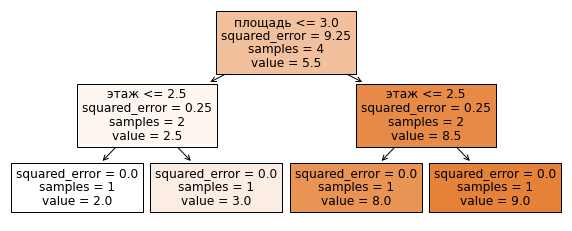

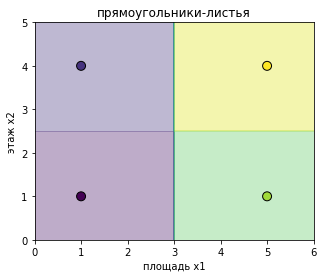

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree

# те же четыре точки
X = np.array([
    [1.0, 1.0],  # A
    [1.0, 4.0],  # B
    [5.0, 1.0],  # C
    [5.0, 4.0],  # D
])
y = np.array([2.0, 3.0, 8.0, 9.0])

# ----- обычный код: один сплит руками -----
j, s = 0, 3.0                          # признак x1, порог 3
left = X[:, j] <= s
right = ~left
c_L = y[left].mean()
c_R = y[right].mean()

def predict_one_split(x):
    return c_L if x[j] <= s else c_R

print("лево", X[left], "c_L", c_L)
print("право", X[right], "c_R", c_R)
print("прогноз для (2,1)", predict_one_split(np.array([2.0, 1.0])))

mse_before = np.mean((y - y.mean()) ** 2)
mse_after = (
    left.mean() * np.mean((y[left] - c_L) ** 2)
    + right.mean() * np.mean((y[right] - c_R) ** 2)
)
print("MSE до", mse_before, "после", mse_after)

# ----- sklearn: полное дерево из вложенных сплитов -----
tree = DecisionTreeRegressor(max_depth=2, random_state=0)
tree.fit(X, y)
print("прогнозы sklearn", tree.predict(X))
print("пороги в вершинах", tree.tree_.threshold[:3])
print("признаки в вершинах", tree.tree_.feature[:3])

plt.figure(figsize=(10, 4))
plot_tree(tree, feature_names=["площадь", "этаж"], filled=True)
plt.show()

# ступеньки на плоскости — формула sum c_m 1{x in R_m}
xx, yy = np.meshgrid(
    np.linspace(0, 6, 200),
    np.linspace(0, 5, 200),
)
grid = np.c_[xx.ravel(), yy.ravel()]
zz = tree.predict(grid).reshape(xx.shape)
plt.figure(figsize=(5, 4))
plt.contourf(xx, yy, zz, levels=10, alpha=0.35)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k", s=80)
plt.xlabel("площадь x1")
plt.ylabel("этаж x2")
plt.title("прямоугольники-листья")
plt.show()

In [55]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

# ----- классификация: 6 синих + 2 оранжевых -----
# класс 0 = синий, класс 1 = оранжевый
y_clf = np.array([0, 0, 0, 0, 0, 0, 1, 1])
# фиктивный признак, чтобы задать тот же сплит: первые 4 влево
x_clf = np.array([1, 1, 1, 1, 3, 3, 3, 3]).reshape(-1, 1)

def gini(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return 1 - np.sum(p ** 2)

def misclass(labels):
    _, counts = np.unique(labels, return_counts=True)
    return 1 - counts.max() / counts.sum()

parent = y_clf
left, right = y_clf[:4], y_clf[4:]
print("родитель gini", gini(parent), "mis", misclass(parent))
print("лево    gini", gini(left), "mis", misclass(left))
print("право   gini", gini(right), "mis", misclass(right))
n, nL, nR = len(parent), len(left), len(right)
print("Q_split gini", nL/n*gini(left) + nR/n*gini(right))
print("Q_split mis ", nL/n*misclass(left) + nR/n*misclass(right))
print("выигрыш gini", gini(parent) - (nL/n*gini(left) + nR/n*gini(right)))
print("выигрыш mis ", misclass(parent) - (nL/n*misclass(left) + nR/n*misclass(right)))

# доли в листе как на первом слайде
leaf = np.array([1, 1, 2, 2, 2, 2, 2, 3])
vals, cnt = np.unique(leaf, return_counts=True)
p = cnt / cnt.sum()
print("p_mk", dict(zip(vals, p)), "k(m)", vals[np.argmax(p)])

clf = DecisionTreeClassifier(criterion="gini", max_depth=1, random_state=0)
clf.fit(x_clf, y_clf)
print("sklearn gini split threshold", clf.tree_.threshold[0])
print("predict_proba листа", clf.predict_proba([[1], [3]]))

# ----- регрессия: шесть точек -----
x = np.array([1, 2, 3, 4, 5, 6], dtype=float)
y = np.array([1, 2, 2, 8, 9, 9], dtype=float)

def sse_split(s):
    L, R = y[x <= s], y[x > s]
    cL, cR = L.mean(), R.mean()
    return np.sum((L - cL) ** 2) + np.sum((R - cR) ** 2), cL, cR

for s in (1.5, 3.5):
    sse, cL, cR = sse_split(s)
    print(f"s={s}: cL={cL:.3f}, cR={cR:.3f}, SSE={sse:.3f}")

reg = DecisionTreeRegressor(criterion="squared_error", max_depth=1, random_state=0)
reg.fit(x.reshape(-1, 1), y)
print("sklearn threshold", reg.tree_.threshold[0])
print("sklearn leaf values", reg.tree_.value.ravel())

родитель gini 0.375 mis 0.25
лево    gini 0.0 mis 0.0
право   gini 0.5 mis 0.5
Q_split gini 0.25
Q_split mis  0.25
выигрыш gini 0.125
выигрыш mis  0.0
p_mk {1: 0.25, 2: 0.625, 3: 0.125} k(m) 2
sklearn gini split threshold 2.0
predict_proba листа [[1.  0. ]
 [0.5 0.5]]
s=1.5: cL=1.000, cR=6.000, SSE=54.000
s=3.5: cL=1.667, cR=8.667, SSE=1.333
sklearn threshold 3.5
sklearn leaf values [5.16666667 1.66666667 8.66666667]


In [56]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier

x = np.array([1., 1., 2., 4., 5., 7.])
y = np.array([0, 0, 1, 1, 1, 0])

def gini(labels):
    if len(labels) == 0:
        return 0.0
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return 1.0 - np.sum(p ** 2)

def find_thresholds_and_scores(feature, target):
    # как на слайде и в указаниях ДЗ
    order = np.argsort(feature)
    feat, lab = feature[order], target[order]
    uniq = np.unique(feat)
    thresholds = (uniq[:-1] + uniq[1:]) / 2.0

    scores = []
    for s in thresholds:
        left, right = lab[feat <= s], lab[feat > s]
        # пустой ребёнок на серединах уникальных не появится
        q = (len(left) * gini(left) + len(right) * gini(right)) / len(lab)
        scores.append(q)
        print(f"s={s:.1f}  L={list(left)}  R={list(right)}  Q_split={q:.3f}")

    scores = np.asarray(scores)
    best = int(np.argmin(scores))
    # при равенстве argmin уже берёт первый, то есть меньший порог
    return thresholds, scores, thresholds[best], scores[best]

thr, q, s_best, q_best = find_thresholds_and_scores(x, y)
print("лучший порог", s_best, "Q", q_best)

# тот же узел в sklearn: одно дерево, глубина 1, один признак
clf = DecisionTreeClassifier(criterion="gini", max_depth=1, random_state=0)
clf.fit(x.reshape(-1, 1), y)
print("sklearn threshold", clf.tree_.threshold[0])
print("sklearn children n", clf.tree_.n_node_samples[1], clf.tree_.n_node_samples[2])

# рекурсия: глубина 2 — второй сплит уже только в правом ребёнке
clf2 = DecisionTreeClassifier(criterion="gini", max_depth=2, random_state=0)
clf2.fit(x.reshape(-1, 1), y)
print("пороги всех вершин", clf2.tree_.threshold)

s=1.5  L=[0, 0]  R=[1, 1, 1, 0]  Q_split=0.250
s=3.0  L=[0, 0, 1]  R=[1, 1, 0]  Q_split=0.444
s=4.5  L=[0, 0, 1, 1]  R=[1, 0]  Q_split=0.500
s=6.0  L=[0, 0, 1, 1, 1]  R=[0]  Q_split=0.400
лучший порог 1.5 Q 0.25
sklearn threshold 1.5
sklearn children n 2 4
пороги всех вершин [ 1.5 -2.   6.  -2.  -2. ]


In [57]:
import numpy as np
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

rng = np.random.default_rng(0)
X, y = make_moons(n_samples=80, noise=0.30, random_state=0)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.35, random_state=0, stratify=y
)

# ----- pre-pruning: те же правила, что на слайде -----
pre = DecisionTreeClassifier(
    max_depth=3,
    min_samples_split=8,
    min_samples_leaf=4,
    min_impurity_decrease=0.01,   # это epsilon для Delta Q
    random_state=0,
)
pre.fit(X_tr, y_tr)
print("pre-pruning  depth", pre.get_depth(), "leaves", pre.get_n_leaves())
print("  train", pre.score(X_tr, y_tr), "test", pre.score(X_te, y_te))

# ----- полное дерево, потом weakest-link через ccp_alpha -----
full = DecisionTreeClassifier(random_state=0)
full.fit(X_tr, y_tr)
print("полное       depth", full.get_depth(), "leaves", full.get_n_leaves())
print("  train", full.score(X_tr, y_tr), "test", full.score(X_te, y_te))

path = full.cost_complexity_pruning_path(X_tr, y_tr)
alphas = path.ccp_alphas
print("цепочка alpha", np.round(alphas, 4))

# каждое alpha -> вложенное дерево T_k
rows = []
for a in alphas:
    t = DecisionTreeClassifier(ccp_alpha=a, random_state=0)
    t.fit(X_tr, y_tr)
    rows.append((a, t.get_n_leaves(), t.score(X_tr, y_tr), t.score(X_te, y_te)))

best = max(rows, key=lambda r: r[3])
print("лучшее по test: alpha", best[0], "листьев", best[1], "test", best[3])

# ----- bias-variance картинка по глубине -----
print("глубина | train | test | gap")
for d in range(1, 9):
    t = DecisionTreeClassifier(max_depth=d, random_state=0)
    t.fit(X_tr, y_tr)
    tr, te = t.score(X_tr, y_tr), t.score(X_te, y_te)
    print(f"{d:7d} | {tr:.3f} | {te:.3f} | {tr-te:.3f}")

pre-pruning  depth 3 leaves 4
  train 0.9038461538461539 test 0.8571428571428571
полное       depth 9 leaves 10
  train 1.0 test 0.9642857142857143
цепочка alpha [0.     0.0144 0.0216 0.0297 0.1165 0.2222]
лучшее по test: alpha 0.0 листьев 10 test 0.9642857142857143
глубина | train | test | gap
      1 | 0.808 | 0.821 | -0.014
      2 | 0.904 | 0.857 | 0.047
      3 | 0.904 | 0.857 | 0.047
      4 | 0.904 | 0.857 | 0.047
      5 | 0.942 | 0.964 | -0.022
      6 | 0.942 | 0.857 | 0.085
      7 | 0.981 | 0.964 | 0.016
      8 | 0.981 | 0.964 | 0.016


In [58]:
import numpy as np
from itertools import combinations
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier

# ----- суррогат: Agree руками -----
area = np.array([1., 2., 5., np.nan])
floor = np.array([2., 1., 8., 7.])
s_main, s_surr = 3.0, 4.0
obs = ~np.isnan(area)
same = (area[obs] <= s_main) == (floor[obs] <= s_surr)
print("Agree", same.mean(), "дырявая точка пойдёт",
      "налево" if floor[3] <= s_surr else "направо")

# ----- кардинальность -----
for K in (2, 3, 4, 20):
    print(f"K={K:2d}  сплитов {2**(K-1) - 1}")

# ----- permutation test ровно как на слайде -----
x = np.arange(1, 9, dtype=float)
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

def T_stat(x, y):
    return abs(x[y == 1].mean() - x[y == 0].mean())

T_obs = T_stat(x, y)
print("T_obs", T_obs)

idx = np.arange(8)
extreme = 0
for ones in combinations(idx, 4):
    y_perm = np.zeros(8, dtype=int)
    y_perm[list(ones)] = 1
    if T_stat(x, y_perm) >= T_obs - 1e-12:
        extreme += 1
print("хвост", extreme, "из", 70, "доля", extreme / 70)

# оценка со слайда с +1: здесь M случайных, не все 70
rng = np.random.default_rng(0)
M = 199
count = 0
for _ in range(M):
    if T_stat(x, rng.permutation(y)) >= T_obs:
        count += 1
p_hat = (1 + count) / (M + 1)
print("p с поправкой +1", p_hat)

# ----- selection bias: шум, разные K -----
rng = np.random.default_rng(1)
n, n_sim = 40, 80
wins = {2: 0, 8: 0, 32: 0}

def make_feature(k):
    return rng.integers(0, k, size=n).astype(float)

for _ in range(n_sim):
    y_noise = rng.integers(0, 2, size=n)
    X = np.column_stack([make_feature(2), make_feature(8), make_feature(32)])
    t = DecisionTreeClassifier(max_depth=1, random_state=0)
    t.fit(X, y_noise)
    wins[[2, 8, 32][t.tree_.feature[0]]] += 1
print("как часто корень взял признак с K=", {k: w / n_sim for k, w in wins.items()})

# ----- ансамбли: те же данные, разные лекарства -----
X_m, y_m = x.reshape(-1, 1), y
for name, model in [
    ("CART", DecisionTreeClassifier(random_state=0)),
    ("RF", RandomForestClassifier(n_estimators=50, random_state=0)),
    ("Extra", ExtraTreesClassifier(n_estimators=50, random_state=0)),
    ("GBDT", GradientBoostingClassifier(random_state=0)),
]:
    model.fit(X_m, y_m)
    print(name, "train acc", model.score(X_m, y_m))

Agree 1.0 дырявая точка пойдёт направо
K= 2  сплитов 1
K= 3  сплитов 3
K= 4  сплитов 7
K=20  сплитов 524287
T_obs 4.0
хвост 2 из 70 доля 0.02857142857142857
p с поправкой +1 0.035
как часто корень взял признак с K= {2: 0.0625, 8: 0.3875, 32: 0.55}
CART train acc 1.0
RF train acc 1.0
Extra train acc 1.0
GBDT train acc 1.0


In [59]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.utils import resample

rng = np.random.default_rng(0)

# пять точек: y = 2x + шум
x = np.array([1., 2., 3., 4., 5.])
y = np.array([2.1, 3.8, 6.4, 7.7, 10.2])
X = x.reshape(-1, 1)
x_new = np.array([[3.0]])          # одна новая квартира

# ----- бутстрэп руками -----
n, B = len(y), 5
print("исходный S индексы", np.arange(n))
for b in range(B):
    idx = rng.choice(n, size=n, replace=True)   # с возвращением
    print(f"S^({b+1}) индексы {idx}  уникальных {len(np.unique(idx))}")

# ----- три дерева на трёх копиях, потом среднее -----
preds = []
for b in range(3):
    idx = rng.choice(n, size=n, replace=True)
    tree = DecisionTreeRegressor(random_state=b)   # глубокое, без pruning
    tree.fit(X[idx], y[idx])
    pred = float(tree.predict(x_new))
    preds.append(pred)
    print(f"дерево {b+1} сказало {pred:.2f}")

print("бэггинг среднее", np.mean(preds))

# ----- sklearn: то же самое -----
bag = BaggingRegressor(
    estimator=DecisionTreeRegressor(),
    n_estimators=20,
    bootstrap=True,
    random_state=0,
)
bag.fit(X, y)
print("sklearn bag pred", float(bag.predict(x_new)))
print("sklearn среднее по деревьям",
      np.mean([t.predict(x_new) for t in bag.estimators_]))

# ----- формула variance: независимые vs rho -----
sigma2, rho, Bv = 4.0, 0.5, 4
print("независимые  sigma2/B =", sigma2 / Bv)
print("с корреляцией", rho * sigma2 + (1 - rho) * sigma2 / Bv)
print("пол при B->inf", rho * sigma2)

# ----- как выглядит пол: много копий, предсказания коррелируют -----
many = []
for b in range(40):
    idx = rng.choice(n, size=n, replace=True)
    t = DecisionTreeRegressor()
    t.fit(X[idx], y[idx])
    many.append(float(t.predict(x_new)))
many = np.asarray(many)
print("var одного дерева", many.var(ddof=1))
print("var среднего первых 4", many[:4].mean())  # одно число
# грубая оценка rho: корреляция соседних прогнозов
print("пример corr двух половин",
      np.corrcoef(many[:20], many[20:])[0, 1])

исходный S индексы [0 1 2 3 4]
S^(1) индексы [4 3 2 1 1]  уникальных 4
S^(2) индексы [0 0 0 0 4]  уникальных 2
S^(3) индексы [3 4 2 3 4]  уникальных 3
S^(4) индексы [3 3 2 2 4]  уникальных 3
S^(5) индексы [1 4 3 0 1]  уникальных 4
дерево 1 сказало 6.40
дерево 2 сказало 2.10
дерево 3 сказало 6.40
бэггинг среднее 4.966666666666668


TypeError: __init__() got an unexpected keyword argument 'estimator'

In [60]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance

rng = np.random.default_rng(0)
X, y = make_classification(
    n_samples=80, n_features=9, n_informative=3, n_redundant=0,
    flip_y=0.1, random_state=0
)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0)

# ----- (1-1/n)^n -----
for n in (5, 20, 100):
    print(f"n={n}  P(OOB)={(1-1/n)**n:.4f}")

# ----- бэггинг vs RF: m=p против m=sqrt(p) -----
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=30, random_state=0
)
rf = RandomForestClassifier(
    n_estimators=30, max_features="sqrt",   # m = sqrt(9) = 3
    bootstrap=True, oob_score=True, random_state=0
)
bag.fit(X_tr, y_tr)
rf.fit(X_tr, y_tr)
print("bag test", bag.score(X_te, y_te), "rf test", rf.score(X_te, y_te))
print("rf oob_score_", rf.oob_score_)

# ----- OOB руками для одной точки -----
# estimators_samples_ есть у Bagging, у RF — через estimator
# для RF sklearn уже усреднил OOB в oob_prediction_
print("oob pred первых 3", rf.oob_decision_function_[:3])

# сколько признаков реально смотрели в корне первого дерева
# (косвенно: max_features_)
print("p=", X.shape[1], "m=", rf.max_features_)

# ----- MDI vs permutation -----
print("MDI", np.round(rf.feature_importances_, 3))
pi = permutation_importance(rf, X_te, y_te, n_repeats=20, random_state=0)
print("PI ", np.round(pi.importances_mean, 3))

# ----- регрессия: не забыть задать m -----
from sklearn.ensemble import RandomForestRegressor
rfr_bad = RandomForestRegressor(n_estimators=20, random_state=0)  # m=p, это бэггинг
rfr_ok = RandomForestRegressor(n_estimators=20, max_features=1.0/3, random_state=0)
print("reg max_features по умолчанию", rfr_bad.max_features)

n=5  P(OOB)=0.3277
n=20  P(OOB)=0.3585
n=100  P(OOB)=0.3660


TypeError: __init__() got an unexpected keyword argument 'estimator'

In [61]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier
)

rng = np.random.default_rng(0)
x = np.array([1., 2., 3., 5., 8., 10.])
y = np.array([0, 0, 0, 1, 1, 1])

def gini(labels):
    _, c = np.unique(labels, return_counts=True)
    p = c / c.sum()
    return 1.0 - np.sum(p ** 2)

def delta_q(x, y, s):
    left, right = y[x <= s], y[x > s]
    if len(left) == 0 or len(right) == 0:
        return 0.0
    n = len(y)
    return gini(y) - (len(left)/n)*gini(left) - (len(right)/n)*gini(right)

# ExtraTrees в одном узле: один случайный порог из Unif(min, max)
lo, hi = x.min(), x.max()
print("диапазон", lo, hi)
for seed in (1, 2, 3):
    s = rng.uniform(lo, hi)
    print(f"s={s:.2f}  DeltaQ={delta_q(x, y, s):.3f}")

# RF в том же узле: все середины уникальных
uniq = np.unique(x)
mids = (uniq[:-1] + uniq[1:]) / 2
print("RF-середины", mids)
print("лучшие RF DeltaQ", max(delta_q(x, y, s) for s in mids))

# ----- три ансамбля на одних данных -----
X, yb = make_classification(
    n_samples=200, n_features=12, n_informative=4, random_state=0
)
X_tr, X_te, y_tr, y_te = train_test_split(X, yb, test_size=0.3, random_state=0)

models = {
    "bag": BaggingClassifier(
        estimator=DecisionTreeClassifier(), n_estimators=40, random_state=0
    ),
    "rf": RandomForestClassifier(
        n_estimators=40, max_features="sqrt", random_state=0
    ),
    "et": ExtraTreesClassifier(
        n_estimators=40, max_features="sqrt", random_state=0
    ),
}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    print(name, "test", round(m.score(X_te, y_te), 3))

print("ET bootstrap по умолчанию", ExtraTreesClassifier().bootstrap)

диапазон 1.0 10.0
s=6.73  DeltaQ=0.250
s=3.43  DeltaQ=0.500
s=1.37  DeltaQ=0.100
RF-середины [1.5 2.5 4.  6.5 9. ]
лучшие RF DeltaQ 0.5


TypeError: __init__() got an unexpected keyword argument 'estimator'

In [62]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

x = np.array([1., 2., 4., 5.])
y = np.array([1., 2., 8., 9.])
X = x.reshape(-1, 1)

# одно дерево = линейная регрессия на индикаторах листьев
tree = DecisionTreeRegressor(max_depth=1, random_state=0)
tree.fit(X, y)
leaf_id = tree.apply(X)                       # номер листа для каждой точки
Phi = OneHotEncoder(sparse_output=False).fit_transform(leaf_id.reshape(-1, 1))
lin = LinearRegression(fit_intercept=False).fit(Phi, y)
print("константы листьев дерева", tree.tree_.value.ravel())
print("веса линейной модели  ", lin.coef_)
print("совпали", np.allclose(tree.predict(X), lin.predict(Phi)))

# лес: сумма вкладов листьев / B
rf = RandomForestRegressor(n_estimators=2, max_depth=1, random_state=0)
rf.fit(X, y)
x_new = np.array([[4.0]])
parts = [float(t.predict(x_new)) for t in rf.estimators_]
print("вклады двух деревьев", parts)
print("среднее", np.mean(parts), "rf.predict", float(rf.predict(x_new)))

# таблица слайда «что имеем» — три модели
for name, m in [
    ("bag-like RF m=p", RandomForestRegressor(n_estimators=20, max_features=1.0, random_state=0)),
    ("RF m=1", RandomForestRegressor(n_estimators=20, max_features=1, random_state=0)),
    ("ET", ExtraTreesRegressor(n_estimators=20, random_state=0)),
]:
    m.fit(X, y)
    print(name, "pred at 4", float(m.predict(x_new)))

TypeError: __init__() got an unexpected keyword argument 'sparse_output'